In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
dataset = pd.read_csv('http://opendata.cern.ch/record/5203/files/Jpsimumu.csv')
dataset

,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,Q1,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2
0,165617,75206813,G,10.1623,0.4763,-8.5164,5.5231,8.5297,0.6091,-1.5149,-1,G,19.7754,2.7508,-13.9871,13.7059,14.2550,0.8539,-1.3766,1
1,165617,75678475,G,15.8799,15.0618,-1.6658,-4.7464,15.1536,-0.3083,-0.1102,1,G,11.9338,11.9084,-0.7670,-0.0851,11.9330,-0.0071,-0.0643,-1
2,165617,74428554,G,21.8279,-6.2214,11.0845,17.7447,12.7111,1.1357,2.0823,-1,G,36.6513,-10.6874,15.0692,31.6544,18.4743,1.3076,2.1877,1
3,165617,75193169,G,19.4923,2.7612,-5.5769,-18.4719,6.2230,-1.8084,-1.1111,1,G,14.9334,1.5525,-6.1254,-13.5302,6.3190,-1.5050,-1.3226,-1
4,165617,74832715,G,8.0972,4.6127,-1.8389,6.3949,4.9657,1.0710,-0.3793,-1,T,3.5131,-0.5305,0.6880,3.4024,0.8688,2.0742,2.2276,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,163796,127190648,G,20.3600,9.1811,7.6371,-16.4894,11.9423,-1.1267,0.6939,-1,G,8.1878,4.2811,4.4597,-5.3678,6.1819,-0.7851,0.8058,1
19996,163796,127218144,G,11.4697,-1.6944,6.4898,-9.3035,6.7073,-1.1304,1.8262,-1,G,12.0051,-2.2652,9.0200,-7.5908,9.3001,-0.7453,1.8168,1
19997,163796,127418342,G,7.8173,4.7081,-4.8603,-3.9128,6.7668,-0.5501,-0.8013,1,G,10.7875,7.8230,-3.5396,-6.5291,8.5865,-0.7014,-0.4249,-1
19998,163796,127439838,G,11.2399,-8.7510,-5.7406,-4.0975,10.4658,-0.3821,-2.5610,1,G,17.7455,-12.2635,-11.9949,-4.5412,17.1543,-0.2617,-2.3673,-1


$$
m c^2 = \sqrt{ \left(E_1+E_2\right)^2 - \left( \left(p_{x_1} + p_{x_2}\right)^2 + \left(p_{y_1} + p_{y_2}\right)^2 + \left(p_{z_1} + p_{z_2}\right)^2 \right)}
$$

In [8]:
dataset['massa_invariante']=np.sqrt((dataset['E1']+dataset['E2'])**2-((dataset['px1']+dataset['px2'])**2+(dataset['py1']+dataset['py2'])**2+(dataset['pz1']+dataset['pz2'])**2))
dataset['massa_invariante']

0        3.112837
1        4.116833
2        3.101969
3        2.332934
4        4.563228
           ...   
19995    3.110674
19996    3.068637
19997    3.085210
19998    3.060899
19999    3.123252
Name: massa_invariante, Length: 20000, dtype: float64

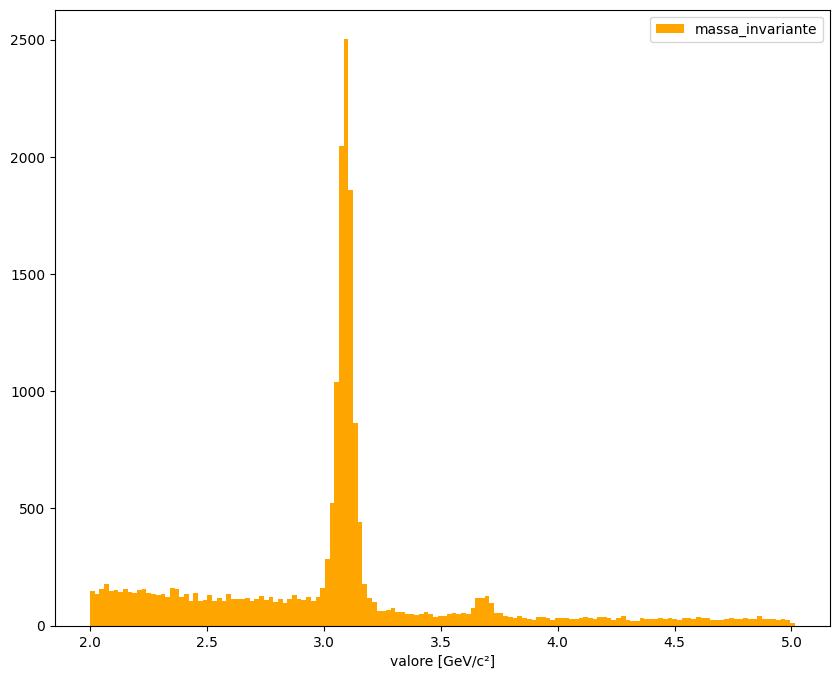

In [31]:
plt.figure(figsize=(10,8))
plt.hist(dataset['massa_invariante'],bins=150,color='orange',label='massa_invariante')
plt.legend()
plt.xlabel('valore')
plt.xlabel('valore [GeV/c²]')
plt.savefig('m_inv.png')
plt.show()

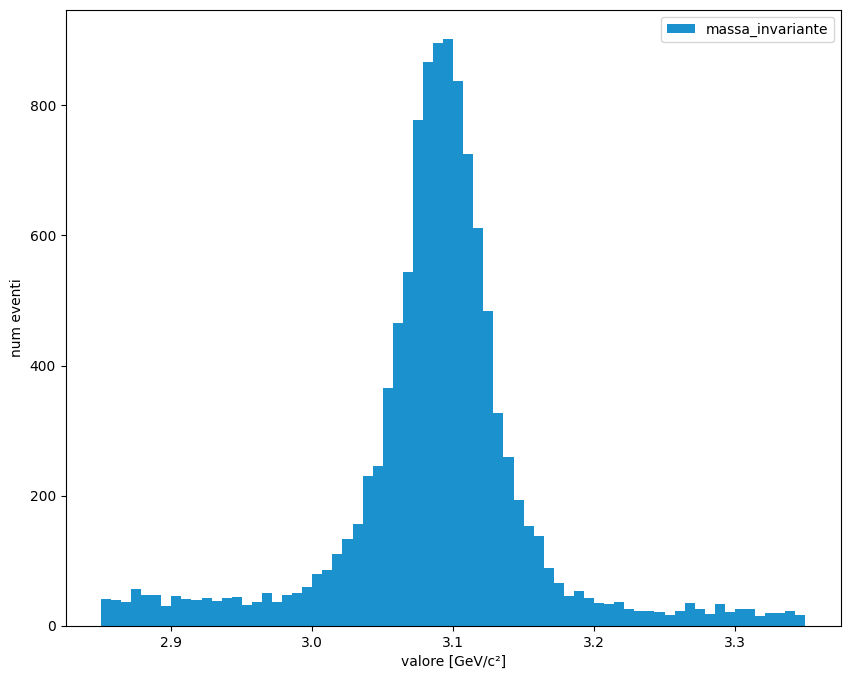

In [33]:
ds = dataset[dataset['massa_invariante'].between(2.85, 3.35)]

plt.figure(figsize=(10, 8))
plt.hist(ds['massa_invariante'], bins=70, color="#1b92cd", label='massa_invariante')
plt.legend()
plt.xlabel('valore [GeV/c²]')
plt.ylabel('num eventi')
plt.savefig('m_inv_zoom.png', bbox_inches='tight')
plt.show()

In [ ]:
from scipy import optimize
def f_g1(x, A, mu, sigma, m, q):
    """
    Funzione di fit: Gaussiana + polinomio di primo grado (retta).
    
    Parametri:
    - x: variabile indipendente (es. massa invariante)
    - A: ampiezza (altezza) del picco gaussiano
    - mu: media (posizione centrale del picco)
    - sigma: deviazione standard (larghezza del picco)
    - m: coefficiente angolare del fondo lineare
    - q: intercetta del fondo lineare
    """
    gauss = A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    poly1 = m * x + q
    return gauss + poly1

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\p'
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\1343376515.py:20: SyntaxWarning: invalid escape sequence '\m'
  plt.title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²')
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\1343376515.py:20: SyntaxWarning: invalid escape sequence '\p'
  plt.title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²')


[ 3.79466085e+02  3.09288075e+00  3.07556032e-02 -2.46191807e+01
  9.14662609e+01] [5.40355237e+00 3.62435563e-04 3.16994108e-04 2.18114007e+00
 6.89458297e+00]


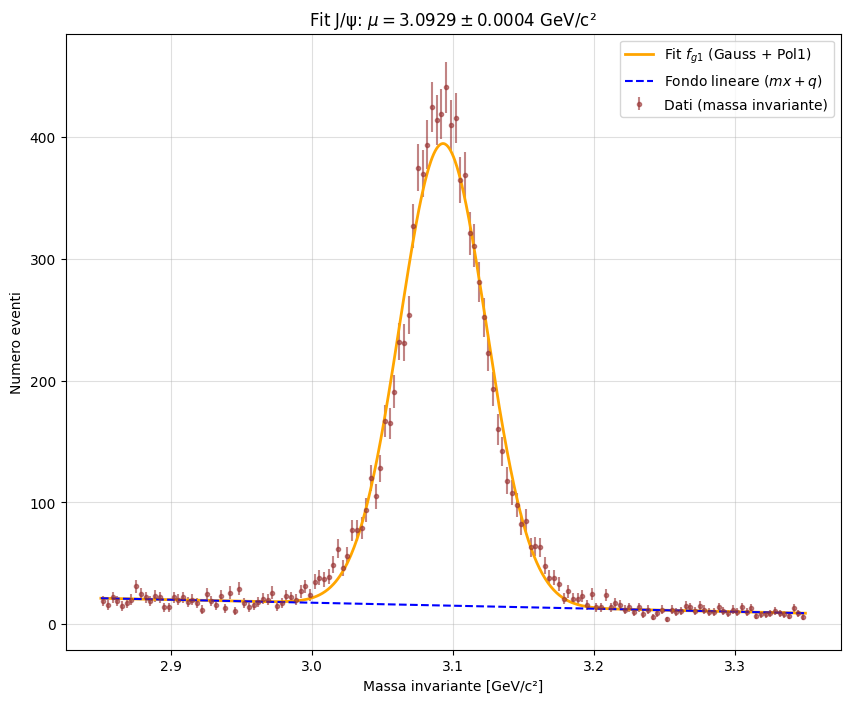

In [46]:
# 2. Estrazione dei dati dall'istogramma (senza disegnarlo subito)
counts, bin_edges = np.histogram(ds['massa_invariante'], bins=150)

# Calcola il centro di ciascun bin (lunghezza = len(bin_edges) - 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
y_err=np.sqrt(counts)
par, pc= optimize.curve_fit(f_g1,bin_centers, counts,sigma=y_err ,absolute_sigma=True)
perr = np.sqrt(np.diag(pc))
print(par,perr)

plt.figure(figsize=(10, 8))
plt.errorbar(bin_centers, counts,yerr=y_err, fmt='.',color="#983232", alpha=0.6, label='Dati (massa invariante)')

x_plot = np.linspace(bin_edges[0], bin_edges[-1], 1000)
plt.plot(x_plot, f_g1(x_plot, *par), color='orange', linewidth=2, label='Fit $f_{g1}$ (Gauss + Pol1)')
plt.plot(x_plot, par[3]*x_plot + par[4], color='blue', linestyle='--', label='Fondo lineare ($mx + q$)')

plt.xlabel('Massa invariante [GeV/c²]')
plt.ylabel('Numero eventi')
plt.title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²')
plt.legend()
plt.grid(True, alpha=0.4)
plt.savefig('m_inv_fit.png', bbox_inches='tight')
plt.show()

<>:62: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\c'
<>:62: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\c'
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\49510396.py:62: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²  |  $\chi^2/ndf = {chi2_rid:.2f}$')
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\49510396.py:62: SyntaxWarning: invalid escape sequence '\p'
  ax1.set_title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²  |  $\chi^2/ndf = {chi2_rid:.2f}$')
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\49510396.py:62: SyntaxWarning: invalid escape sequence '\c'
  ax1.set_title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²  |  $\chi^2/ndf = {chi2_rid:.2f}$')


=== RISULTATI DEL FIT (f_g1) ===
A      = 379.46819 ± 5.40367
mu     = 3.09288 ± 0.00036
sigma  = 0.03076 ± 0.00032
m      = -24.61929 ± 2.18114
q      = 91.46667 ± 6.89458
--------------------------------
Chi2       = 231.27
ndf        = 145
Chi2 / ndf = 1.595


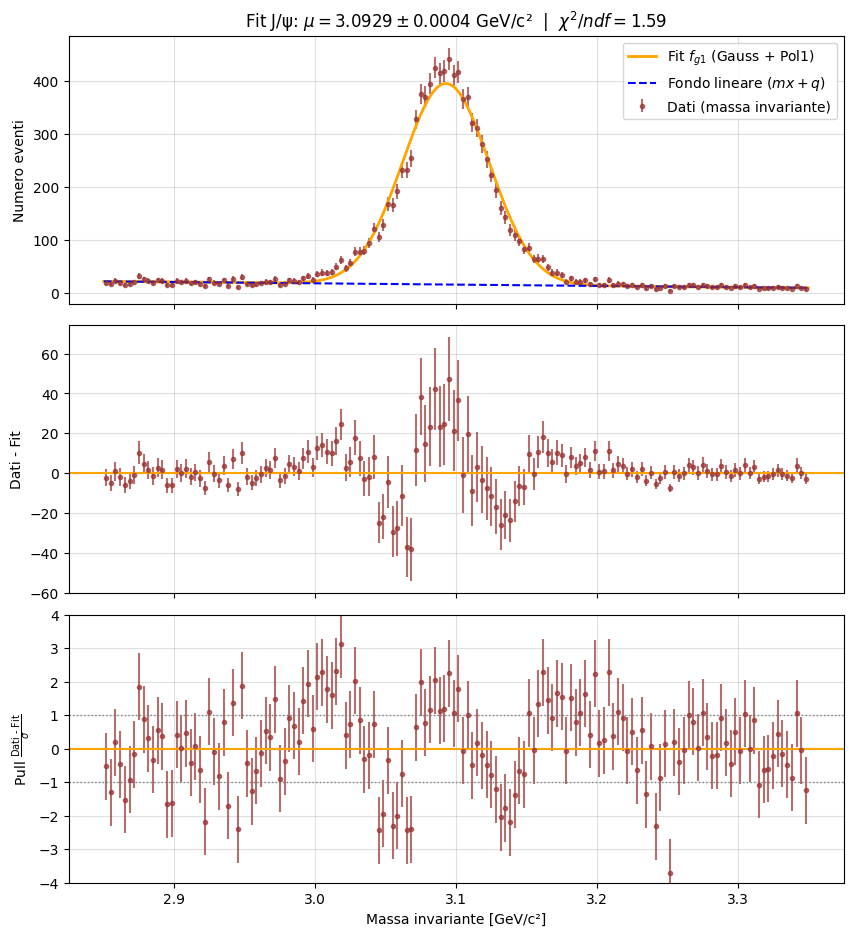

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 1. Estrazione dei dati dall'istogramma
counts, bin_edges = np.histogram(ds['massa_invariante'], bins=150)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
y_err = np.sqrt(counts)

# Stima parametri iniziali p0 = [A, mu, sigma, m, q] per garantire la convergenza
p0 = [np.max(counts) - np.min(counts), bin_centers[np.argmax(counts)], 0.03, 0.0, np.min(counts)]

# 2. Fit con curve_fit
par, pc = optimize.curve_fit(f_g1, bin_centers, counts, p0=p0, sigma=y_err, absolute_sigma=True)
perr = np.sqrt(np.diag(pc))

# 3. Calcolo valori attesi, scarti e Chi-quadro
y_fit = f_g1(bin_centers, *par)
scarti = counts - y_fit                  # Scarto: dati - fit
scarti_norm = scarti / y_err             # Pull: (dati - fit) / errore

chi2 = np.sum(scarti_norm ** 2)
ndf = len(counts) - len(par)             # Gradi di libertà (N_bin - N_parametri)
chi2_rid = chi2 / ndf

# 4. Costruzione del testo dei risultati, stampa e salvataggio su file .txt
nomi_param = ['A', 'mu', 'sigma', 'm', 'q']

righe = ["=== RISULTATI DEL FIT (f_g1) ==="]
for nome, val, err in zip(nomi_param, par, perr):
    righe.append(f"{nome:6s} = {val:.5f} ± {err:.5f}")

righe.append("-" * 32)
righe.append(f"Chi2       = {chi2:.2f}")
righe.append(f"ndf        = {ndf}")
righe.append(f"Chi2 / ndf = {chi2_rid:.3f}")

# Unisce tutte le righe in un'unica stringa separata da a-capo
testo_risultati = "\n".join(righe)

# Stampa a schermo
print(testo_risultati)

# Salva nel file .txt
with open("risultati_fit_g1.txt", "w", encoding="utf-8") as file_out:
    file_out.write(testo_risultati)

# 5. Grafico a 3 pannelli (Dati+Fit, Scarti, Scarti normalizzati)
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, 
    figsize=(10, 11), 
    sharex=True, 
    gridspec_kw={'height_ratios':None, 'hspace': 0.08}
)

# --- PANNELLO 1: Dati e Fit ---
ax1.errorbar(bin_centers, counts, yerr=y_err, fmt='.', color="#983232", alpha=0.7, label='Dati (massa invariante)')
x_plot = np.linspace(bin_edges[0], bin_edges[-1], 1000)
ax1.plot(x_plot, f_g1(x_plot, *par), color='orange', linewidth=2, label='Fit $f_{g1}$ (Gauss + Pol1)')
ax1.plot(x_plot, par[3]*x_plot + par[4], color='blue', linestyle='--', label='Fondo lineare ($mx + q$)')
ax1.set_ylabel('Numero eventi')
ax1.set_title(f'Fit J/ψ: $\mu = {par[1]:.4f} \pm {perr[1]:.4f}$ GeV/c²  |  $\chi^2/ndf = {chi2_rid:.2f}$')
ax1.legend()
ax1.grid(True, alpha=0.4)

# --- PANNELLO 2: Scarto (Dati - Fit) ---
ax2.errorbar(bin_centers, scarti, yerr=y_err, fmt='.', color="#983232", alpha=0.7)
ax2.axhline(0, color='orange', linestyle='-', linewidth=1.5)
ax2.set_ylabel('Dati - Fit')
ax2.grid(True, alpha=0.4)

# --- PANNELLO 3: Scarto normalizzato ((Dati - Fit) / Errore) ---
ax3.errorbar(bin_centers, scarti_norm, yerr=1.0, fmt='.', color="#983232", alpha=0.7)
ax3.axhline(0, color='orange', linestyle='-', linewidth=1.5)
ax3.axhline(1, color='gray', linestyle=':', linewidth=1)
ax3.axhline(-1, color='gray', linestyle=':', linewidth=1)
ax3.set_ylabel('Pull $\\frac{\\text{Dati - Fit}}{\\sigma}$')
ax3.set_xlabel('Massa invariante [GeV/c²]')
ax3.set_ylim(-4, 4)  # Fissa una scala leggibile per i pull (solitamente tra -3 e +3)
ax3.grid(True, alpha=0.4)

plt.savefig('m_inv_fit_completo.png', bbox_inches='tight')
plt.show()


In [55]:
def f_g2(x, A1, A2, mu, sigma1, sigma2, m, q):
    """
    Funzione di fit: Doppia Gaussiana (con media condivisa) + polinomio di primo grado (retta).
    
    Parametri:
    - x: variabile indipendente (es. massa invariante)
    - A1: ampiezza (altezza) della prima gaussiana
    - A2: ampiezza (altezza) della seconda gaussiana
    - mu: media condivisa (posizione centrale dei due picchi)
    - sigma1: deviazione standard (larghezza) della prima gaussiana
    - sigma2: deviazione standard (larghezza) della seconda gaussiana
    - m: coefficiente angolare del fondo lineare
    - q: intercetta del fondo lineare
    """
    gauss1 = A1 * np.exp(-0.5 * ((x - mu) / sigma1) ** 2)
    gauss2 = A2 * np.exp(-0.5 * ((x - mu) / sigma2) ** 2)
    poly1 = m * x + q
    return gauss1 + gauss2 + poly1


<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\p'
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\1874594055.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.title(f'Fit J/ψ: $\mu = {par2[1]:.4f} \pm {perr2[1]:.4f}$ GeV/c²')
C:\Users\mpaol\AppData\Local\Temp\ipykernel_22652\1874594055.py:14: SyntaxWarning: invalid escape sequence '\p'
  plt.title(f'Fit J/ψ: $\mu = {par2[1]:.4f} \pm {perr2[1]:.4f}$ GeV/c²')


[ 2.48482808e+02  1.70001040e+02  3.09278083e+00  2.07860199e-02
  4.05692880e-02 -2.27336550e+01  8.43890420e+01] [2.57624153e+01 2.69504713e+01 3.63176402e-04 1.34262567e-03
 1.82297260e-03 2.20367892e+00 6.99149570e+00]


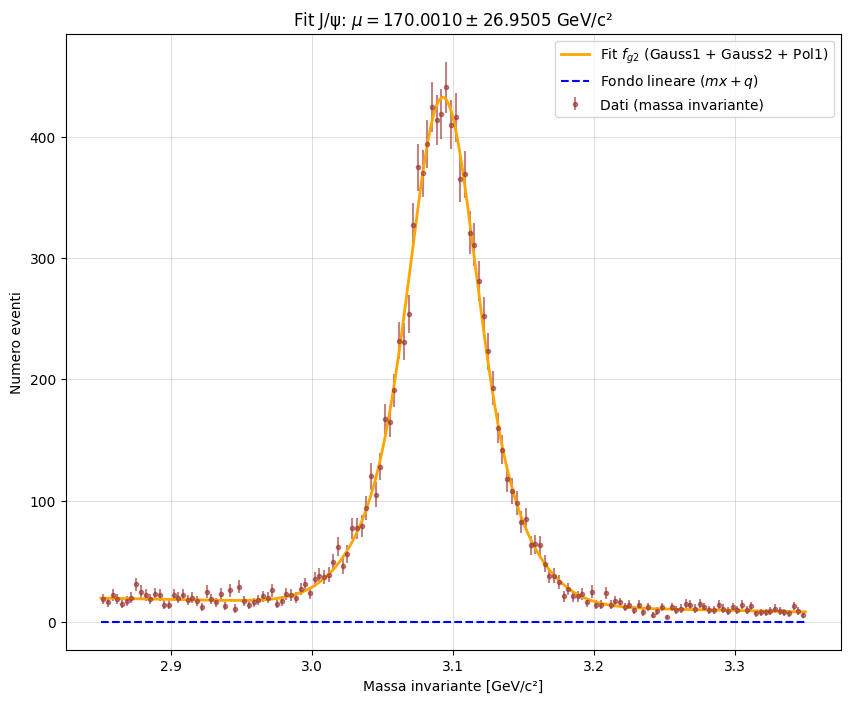

In [ ]:
par2, pc2= optimize.curve_fit(f_g2,bin_centers, counts,sigma=y_err ,absolute_sigma=True)
perr2 = np.sqrt(np.diag(pc2))
print(par2,perr2)

plt.figure(figsize=(10, 8))
plt.errorbar(bin_centers, counts,yerr=y_err, fmt='.',color="#983232", alpha=0.6, label='Dati (massa invariante)')

x_plot = np.linspace(bin_edges[0], bin_edges[-1], 1000)
plt.plot(x_plot, f_g2(x_plot, *par2), color='orange', linewidth=2, label='Fit $f_{g2}$ (Gauss1 + Gauss2 + Pol1)')
plt.plot(x_plot, par2[3]*x_plot + par2[4], color='blue', linestyle='--', label='Fondo lineare ($mx + q$)')

plt.xlabel('Massa invariante [GeV/c²]')
plt.ylabel('Numero eventi')
plt.title(f'Fit J/ψ: $\mu = {par2[1]:.4f} \pm {perr2[1]:.4f}$ GeV/c²')
plt.legend()
plt.grid(True, alpha=0.4)
plt.savefig('m_inv_fit2.png', bbox_inches='tight')
plt.close()

=== RISULTATI DEL FIT (f_g2) ===
A1     = 248.48766 ± 25.76135
A2     = 169.99555 ± 26.94931
mu     = 3.09278 ± 0.00036
sigma1 = 0.02079 ± 0.00134
sigma2 = 0.04057 ± 0.00182
m      = -22.73361 ± 2.20367
q      = 84.38889 ± 6.99146
--------------------------------
Chi2       = 121.57
ndf        = 143
Chi2 / ndf = 0.850


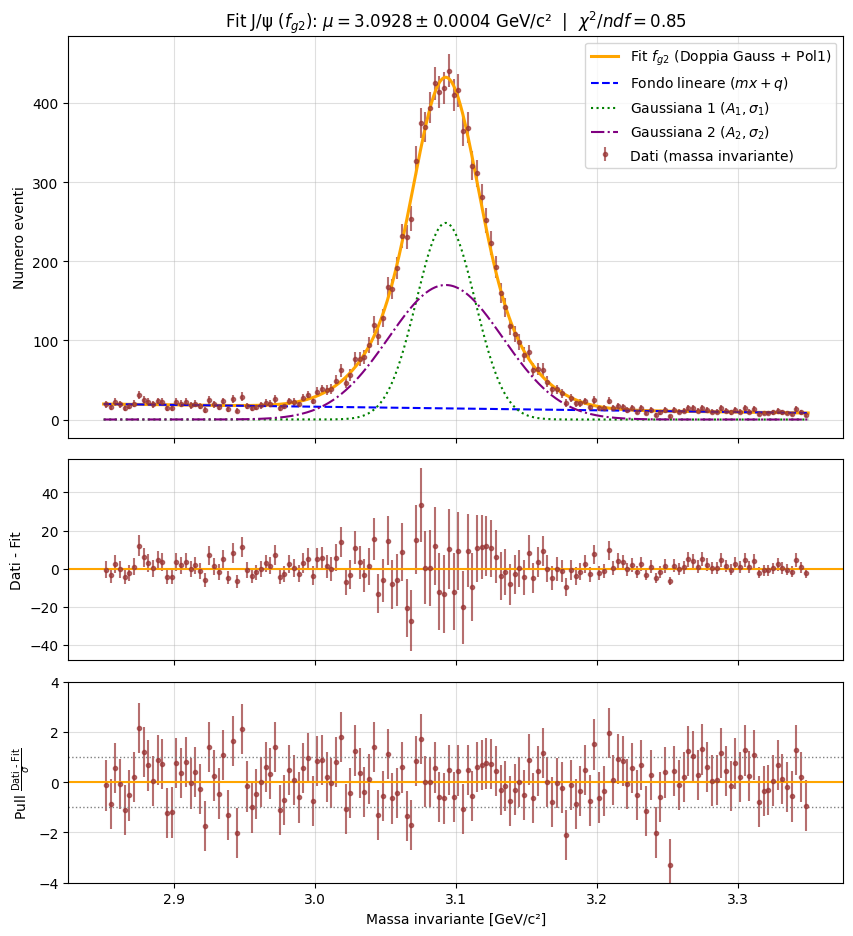

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

# 1. Estrazione dei dati dall'istogramma
counts, bin_edges = np.histogram(ds['massa_invariante'], bins=150)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
y_err = np.sqrt(counts)

# Stima parametri iniziali p0_2 = [A1, A2, mu, sigma1, sigma2, m, q]
A_tot = np.max(counts) - np.min(counts)
mu_init = bin_centers[np.argmax(counts)]
q_init = np.min(counts)
p0_2 = [0.7 * A_tot, 0.3 * A_tot, mu_init, 0.02, 0.05, 0.0, q_init]

# 2. Fit con curve_fit usando f_g2
par2, pc2 = optimize.curve_fit(f_g2, bin_centers, counts, p0=p0_2, sigma=y_err, absolute_sigma=True)
perr2 = np.sqrt(np.diag(pc2))

# 3. Calcolo valori attesi, scarti e Chi-quadro
y_fit2 = f_g2(bin_centers, *par2)
scarti2 = counts - y_fit2                 # Scarto: dati - fit
scarti_norm2 = scarti2 / y_err            # Pull: (dati - fit) / errore

chi2_2 = np.sum(scarti_norm2 ** 2)
ndf_2 = len(counts) - len(par2)           # Gradi di libertà (150 - 7 = 143)
chi2_rid2 = chi2_2 / ndf_2

# 4. Costruzione del testo dei risultati, stampa e salvataggio su file .txt
nomi_param2 = ['A1', 'A2', 'mu', 'sigma1', 'sigma2', 'm', 'q']

righe2 = ["=== RISULTATI DEL FIT (f_g2) ==="]
for nome, val, err in zip(nomi_param2, par2, perr2):
    righe2.append(f"{nome:6s} = {val:.5f} ± {err:.5f}")

righe2.append("-" * 32)
righe2.append(f"Chi2       = {chi2_2:.2f}")
righe2.append(f"ndf        = {ndf_2}")
righe2.append(f"Chi2 / ndf = {chi2_rid2:.3f}")

testo_risultati2 = "\n".join(righe2)

# Stampa a schermo
print(testo_risultati2)

# Salva nel file .txt dedicato a f_g2
with open("risultati_fit_g2.txt", "w", encoding="utf-8") as file_out:
    file_out.write(testo_risultati2)

# 5. Grafico a 3 pannelli (Dati+Fit, Scarti, Scarti normalizzati)
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, 
    figsize=(10, 11), 
    sharex=True, 
    gridspec_kw={'height_ratios':[2,1,1], 'hspace': 0.08}
)

# Calcolo delle componenti singole su x_plot per visualizzarle nel grafico
x_plot = np.linspace(bin_edges[0], bin_edges[-1], 1000)
fondo_plot = par2[5] * x_plot + par2[6]
gaus1_plot = par2[0] * np.exp(-0.5 * ((x_plot - par2[2]) / par2[3]) ** 2)
gaus2_plot = par2[1] * np.exp(-0.5 * ((x_plot - par2[2]) / par2[4]) ** 2)

# --- PANNELLO 1: Dati e Fit ---
ax1.errorbar(bin_centers, counts, yerr=y_err, fmt='.', color="#983232", alpha=0.7, label='Dati (massa invariante)')
ax1.plot(x_plot, f_g2(x_plot, *par2), color='orange', linewidth=2.2, label='Fit $f_{g2}$ (Doppia Gauss + Pol1)')
ax1.plot(x_plot, fondo_plot, color='blue', linestyle='--', label='Fondo lineare ($mx + q$)')
ax1.plot(x_plot, gaus1_plot, color='green', linestyle=':', linewidth=1.5, label='Gaussiana 1 ($A_1, \\sigma_1$)')
ax1.plot(x_plot, gaus2_plot, color='purple', linestyle='-.', linewidth=1.5, label='Gaussiana 2 ($A_2, \\sigma_2$)')

ax1.set_ylabel('Numero eventi')
ax1.set_title(f'Fit J/ψ ($f_{{g2}}$): $\\mu = {par2[2]:.4f} \\pm {perr2[2]:.4f}$ GeV/c²  |  $\\chi^2/ndf = {chi2_rid2:.2f}$')
ax1.legend()
ax1.grid(True, alpha=0.4)

# --- PANNELLO 2: Scarto (Dati - Fit) ---
ax2.errorbar(bin_centers, scarti2, yerr=y_err, fmt='.', color="#983232", alpha=0.7)
ax2.axhline(0, color='orange', linestyle='-', linewidth=1.5)
ax2.set_ylabel('Dati - Fit')
ax2.grid(True, alpha=0.4)

# --- PANNELLO 3: Scarto normalizzato ((Dati - Fit) / Errore) ---
ax3.errorbar(bin_centers, scarti_norm2, yerr=1.0, fmt='.', color="#983232", alpha=0.7)
ax3.axhline(0, color='orange', linestyle='-', linewidth=1.5)
ax3.axhline(1, color='gray', linestyle=':', linewidth=1)
ax3.axhline(-1, color='gray', linestyle=':', linewidth=1)
ax3.set_ylabel('Pull $\\frac{\\text{Dati - Fit}}{\\sigma}$')
ax3.set_xlabel('Massa invariante [GeV/c²]')
ax3.set_ylim(-4, 4)
ax3.grid(True, alpha=0.4)

plt.savefig('m_inv_fit_g2_completo.png', bbox_inches='tight')
plt.show()
